
# Toronto Blue Jays Fielding Analysis (2025 vs. 2026)

## 1. Introduction & Research Objectives

### Background

The Toronto Blue Jays experienced a significant decline in team performance between the 2025 and 2026 MLB seasons, falling from 94 wins to 79 wins.

Previous analyses revealed that Toronto's offensive production declined substantially, while overall run prevention improved.

This notebook examines whether changes in defensive performance contributed to the team's results and whether improved fielding may help explain the reduction in runs allowed.

### Research Questions

1. How did Toronto's traditional defensive statistics change between 2025 and 2026?
2. Did advanced defensive metrics indicate improvement or deterioration?
3. Do traditional and advanced fielding statistics provide consistent assessments of Toronto's defense?
4. How do these defensive findings relate to the team's overall run prevention?

### Analytical Approach

This analysis compares team-level fielding statistics using Python, pandas, NumPy, and matplotlib.

Both traditional defensive statistics and advanced defensive metrics will be examined through summary tables and visualizations.

Because the dataset contains only two seasons of team-level observations, conclusions will focus on descriptive comparisons rather than causal relationships.


In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cleaned team fielding dataset
fielding = pd.read_csv("../data/processed/team_fielding_clean.csv")

# Display the dataset
fielding


,season,defensive_efficiency,chances,putouts,assists,errors,double_plays,fielding_percentage,total_zone_runs,defensive_runs_saved
0,2025,0.700,5672,4314,1272,86,118,0.985,-8,4
1,2026,0.701,5765,4308,1358,99,110,0.983,8,33



## 2. Traditional Fielding Performance

This section compares Toronto's traditional fielding statistics between the 2025 and 2026 seasons.

Errors, fielding percentage, double plays turned, and total fielding chances are examined to identify changes in defensive performance.

These statistics provide an initial assessment of Toronto's defense before considering advanced defensive metrics.


In [2]:

# Select traditional fielding statistics
traditional_stats = [
    "errors",
    "fielding_percentage",
    "double_plays",
    "chances"
]

# Set season as the index and transpose the table
traditional_comparison = fielding.set_index("season")[traditional_stats].T

# Calculate the change from 2025 to 2026
traditional_comparison["Change"] = (
    traditional_comparison[2026] - traditional_comparison[2025]
)

# Display the comparison
traditional_comparison


season,2025,2026,Change
errors,86.000,99.000,13.000
fielding_percentage,0.985,0.983,-0.002
double_plays,118.000,110.000,-8.000
chances,5672.000,5765.000,93.000



### Traditional Fielding Findings

Toronto's traditional fielding statistics showed signs of deterioration between 2025 and 2026.

- **Errors:** Increased from 86 to 99 (+13), representing a 15.1% increase.
- **Fielding percentage:** Declined from .985 to .983, a decrease of 0.2 percentage points.
- **Double plays:** Decreased from 118 to 110 (-8).
- **Total chances:** Increased from 5,672 to 5,765 (+93).

The increase in errors and decline in fielding percentage suggest weaker performance in handling recorded defensive chances.

However, fewer double plays do not necessarily indicate poorer defensive execution, as the number of double-play opportunities may have differed between seasons.

Traditional fielding statistics also provide limited information about defensive range and overall run prevention. Advanced defensive metrics will be examined next to develop a more complete assessment.



## 3. Advanced Defensive Performance

Traditional fielding statistics provide useful information about recorded errors and defensive chances but do not fully capture defensive range and overall effectiveness.

This section compares defensive efficiency, Total Zone Runs (TZR), and Defensive Runs Saved (DRS) to evaluate whether Toronto's broader defensive performance improved or deteriorated.


In [3]:

# Select advanced defensive statistics
advanced_stats = [
    "defensive_efficiency",
    "total_zone_runs",
    "defensive_runs_saved"
]

# Create a comparison table
advanced_comparison = fielding.set_index("season")[advanced_stats].T

# Calculate changes between seasons
advanced_comparison["Change"] = (
    advanced_comparison[2026] - advanced_comparison[2025]
)

# Display results
advanced_comparison


season,2025,2026,Change
defensive_efficiency,0.7,0.701,0.001
total_zone_runs,-8.0,8.000,16.000
defensive_runs_saved,4.0,33.000,29.000



### Advanced Defensive Findings

Toronto's advanced defensive metrics improved between 2025 and 2026, contrasting with the deterioration observed in traditional fielding statistics.

- **Defensive efficiency:** Increased slightly from .700 to .701 (+0.001), indicating relatively stable conversion of balls in play into outs.
- **Total Zone Runs (TZR):** Improved from -8 to +8, a gain of 16 runs relative to the metric's defensive baseline.
- **Defensive Runs Saved (DRS):** Increased from +4 to +33, a gain of 29 estimated runs saved relative to average.

These findings suggest that Toronto's broader defensive performance improved despite committing more errors and recording a lower fielding percentage.

Advanced metrics attempt to capture aspects of defensive performance that traditional statistics may overlook, including range and defensive execution.

However, TZR and DRS are model-based estimates rather than direct measurements of actual runs prevented. Their improvements should therefore not be interpreted as proof that defense caused Toronto's reduction in runs allowed.


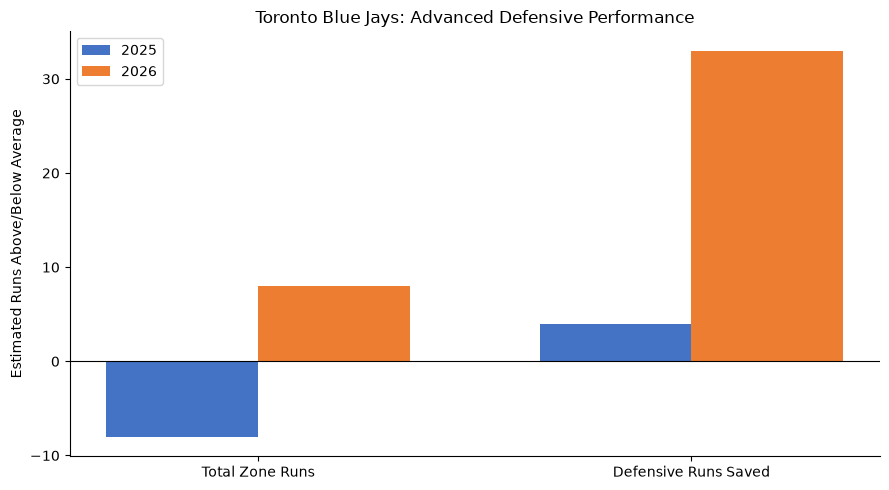

In [4]:

# Select the advanced run-based defensive metrics
metrics = ["total_zone_runs", "defensive_runs_saved"]
labels = ["Total Zone Runs", "Defensive Runs Saved"]

# Retrieve the values for each season
values_2025 = fielding.loc[fielding["season"] == 2025, metrics].iloc[0]
values_2026 = fielding.loc[fielding["season"] == 2026, metrics].iloc[0]

# Set bar positions
x = np.arange(len(metrics))
width = 0.35

# Create the chart
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - width/2, values_2025, width, label="2025", color="#4472C4")
ax.bar(x + width/2, values_2026, width, label="2026", color="#ED7D31")

# Add a zero reference line
ax.axhline(0, color="black", linewidth=0.8)

# Format the chart
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Estimated Runs Above/Below Average")
ax.set_title("Toronto Blue Jays: Advanced Defensive Performance")
ax.legend()

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



## 4. Fielding Performance & Run Prevention

Toronto's overall run prevention improved between 2025 and 2026, with runs allowed declining from 721 to 694 (-27) and team ERA decreasing from 4.19 to 3.89.

Over the same period, Defensive Runs Saved increased by 29 runs and Total Zone Runs improved by 16 runs relative to their respective defensive baselines.

These improvements suggest that stronger defensive performance may have contributed to the team's improved run prevention, despite the increase in recorded fielding errors.

However, advanced defensive metrics are estimates, and their changes cannot be directly equated with actual runs prevented. With only two seasons of team-level observations, the independent contributions of pitching and fielding cannot be determined.

Together, the pitching and fielding analyses suggest that Toronto's decline in overall performance was not driven by worsening team-level run prevention.



## 5. Final Fielding Conclusion

The Toronto Blue Jays' defensive performance showed mixed results between 2025 and 2026, although advanced defensive metrics indicated overall improvement.

Traditional statistics deteriorated, with errors increasing from 86 to 99, fielding percentage declining from .985 to .983, and double plays decreasing from 118 to 110.

However, advanced defensive metrics suggested stronger performance. Total Zone Runs improved from -8 to +8, while Defensive Runs Saved increased from +4 to +33. Defensive efficiency also remained relatively stable, increasing slightly from .700 to .701.

These findings suggest that Toronto's defense improved in aspects not fully captured by traditional fielding statistics. Improved defensive performance may also have contributed to the team's reduction in runs allowed, although its independent impact cannot be established from the available data.

### Connection to the Overall Analysis

Combined with the previous offensive and pitching analyses, the findings reveal a clear pattern:

- **Offense:** Runs scored declined by 150, indicating a substantial reduction in offensive production.
- **Pitching:** Team ERA improved from 4.19 to 3.89, while runs allowed decreased by 27.
- **Fielding:** Advanced defensive metrics improved despite weaker traditional fielding statistics.
- **Run differential:** Declined from +77 to -46, a deterioration of 123 runs.

Overall, the evidence indicates that declining offensive production was the primary statistical driver of Toronto's worsening run differential. Improvements in run prevention, potentially supported by stronger defensive performance, partially offset the offensive decline but were insufficient to prevent the team's overall deterioration.

The next stage of the analysis will examine roster composition and personnel changes to provide additional context for these findings.
